# Model 1: WaterMark Remover

Imports

In [ ]:
from pathlib import Path
import hashlib
import json
import math
import random
from PIL import Image, ImageDraw, ImageFont, ImageOps, ImageChops
from IPython.display import display
import torch
from torch import nn
from torch.nn import functional as F
import random
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader

## Watermark generation

In [ ]:
# Hyperparameters — edit these before running this cell.
MAX_IMAGES = None  # Set to 100 for a quick trial; None uses every photo.

# Dataset download: https://s3.amazonaws.com/fast-ai-imageclas/imagenette2.tgz

SOURCE_DIR = Path('data/watermark_data/watermark_data/imagenette2')  # Recursively finds train/ and val/ photos.
OUTPUT_DIR = Path('data/watermark_data/watermark_pairs_v3')  # Use a new folder for each configuration.
SEED = 42
TEST_FRACTION = 0.2
VARIANTS_PER_IMAGE = 1
TYPE_WEIGHTS = {'text': 0.3, 'logo': 0.7}
TEXTS = ['SAMPLE', 'PREVIEW', 'Your Brand', '© Example Studio']
LOGO_DIR = Path('data/watermark_data/logos')  # Transparent PNG logo assets.
FONT_PATH = None  # Optional path to a .ttf/.otf font.
GRID_ROWS = (3, 6)  # Inclusive range; sampled once per image.
GRID_COLUMNS = (3, 5)  # More rows/columns = higher watermark frequency.
ROW_STAGGER = 0.5  # Alternate rows shift by half a column, like bricks.
CELL_FILL = (0.55, 0.85)  # Mark size relative to its grid cell; smaller = more spacing.
OPACITY = (0.3, 0.7)
ROTATION_DEGREES = (-35, 35)
COLORS = ['white', 'black', '#aaaaaa']


EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}
assert SOURCE_DIR.is_dir(), f'Missing source folder: {SOURCE_DIR.resolve()}'
assert not OUTPUT_DIR.exists(), 'Output folder exists; choose a new OUTPUT_DIR to avoid mixing runs.'
assert 0 < TEST_FRACTION < 1
assert VARIANTS_PER_IMAGE >= 1
assert 1 <= GRID_ROWS[0] <= GRID_ROWS[1]
assert 1 <= GRID_COLUMNS[0] <= GRID_COLUMNS[1]
assert 0 <= ROW_STAGGER < 1
assert 0 < CELL_FILL[0] <= CELL_FILL[1] <= 1
assert 0 < OPACITY[0] <= OPACITY[1] <= 1
assert ROTATION_DEGREES[0] <= ROTATION_DEGREES[1]
assert TEXTS and all(TEXTS) and COLORS
assert TYPE_WEIGHTS and set(TYPE_WEIGHTS) <= {'text', 'logo'}
assert all(v >= 0 for v in TYPE_WEIGHTS.values()) and sum(TYPE_WEIGHTS.values()) > 0
assert MAX_IMAGES is None or MAX_IMAGES >= 2

sources = sorted(p for p in SOURCE_DIR.rglob('*') if p.suffix.lower() in EXTENSIONS)
# Hash the original files so identical copies cannot leak across the split.
groups = {}
for path in sources:
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    groups.setdefault(digest, path)
sources = sorted(groups.items())
rng = random.Random(SEED)
rng.shuffle(sources)
if MAX_IMAGES is not None:
    sources = sources[:MAX_IMAGES]
assert len(sources) >= 2, 'Need at least two unique images.'
n_test = min(len(sources) - 1, max(1, round(len(sources) * TEST_FRACTION)))
logo_paths = []
if LOGO_DIR is not None:
    logo_paths = sorted(p for p in Path(LOGO_DIR).rglob('*') if p.suffix.lower() in EXTENSIONS)
    assert logo_paths, f'No logo images found in {LOGO_DIR}'
font = ImageFont.truetype(str(FONT_PATH), 100) if FONT_PATH else ImageFont.load_default(size=100)


def make_mark(kind, local_rng):
    color = local_rng.choice(COLORS)
    if kind == 'text':
        text = local_rng.choice(TEXTS)
        box = font.getbbox(text)
        mark = Image.new('RGBA', (max(1, box[2] - box[0]) + 16, max(1, box[3] - box[1]) + 16))
        ImageDraw.Draw(mark).text((8 - box[0], 8 - box[1]), text, font=font, fill=color)
        return mark, text
    if logo_paths:
        path = local_rng.choice(logo_paths)
        with Image.open(path) as logo:
            return ImageOps.exif_transpose(logo).convert('RGBA'), str(path)
    # Built-in synthetic logo lets the cell run without external assets.
    mark = Image.new('RGBA', (240, 240))
    draw = ImageDraw.Draw(mark)
    draw.rounded_rectangle((12, 12, 228, 228), radius=45, outline=color, width=16)
    draw.polygon([(120, 40), (202, 182), (38, 182)], outline=color, width=14)
    draw.ellipse((99, 119, 141, 161), fill=color)
    return mark, 'synthetic_triangle_logo'


def add_watermarks(clean, local_rng):
    width, height = clean.size
    composite = clean.convert('RGBA')
    mask = Image.new('L', clean.size, 0)
    records = []
    rows = local_rng.randint(*GRID_ROWS)
    columns = local_rng.randint(*GRID_COLUMNS)
    cell_width, cell_height = width / columns, height / rows
    # Repeat one consistent design/angle/opacity across this image.
    kind = local_rng.choices(list(TYPE_WEIGHTS), weights=list(TYPE_WEIGHTS.values()), k=1)[0]
    mark, content = make_mark(kind, local_rng)
    angle = local_rng.uniform(*ROTATION_DEGREES)
    opacity = local_rng.uniform(*OPACITY)
    fill = local_rng.uniform(*CELL_FILL)
    # Rotate before fitting so neighboring tiles cannot pile onto one another.
    mark = mark.rotate(angle, resample=Image.Resampling.BICUBIC, expand=True)
    scale = min(cell_width * fill / mark.width, cell_height * fill / mark.height)
    mark = mark.resize((max(1, math.floor(mark.width * scale)),
                        max(1, math.floor(mark.height * scale))), Image.Resampling.LANCZOS)
    mark.putalpha(mark.getchannel('A').point(lambda a: round(a * opacity)))
    for row in range(rows):
        shift = ROW_STAGGER if row % 2 else 0
        # Include the left edge tile on shifted rows; clipping is intentional.
        for column in range(-1 if shift else 0, columns):
            x = round((column + 0.5 + shift) * cell_width - mark.width / 2)
            y = round((row + 0.5) * cell_height - mark.height / 2)
            layer = Image.new('RGBA', clean.size)
            layer.alpha_composite(mark, (x, y))
            support = layer.getchannel('A').point(lambda a: 255 if a else 0)
            if support.getbbox() is None:
                continue
            composite = Image.alpha_composite(composite, layer)
            mask = ImageChops.lighter(mask, support)
            records.append(dict(kind=kind, content=content, opacity=opacity, angle=angle,
                                grid_rows=rows, grid_columns=columns, row=row, column=column,
                                row_stagger=ROW_STAGGER, cell_fill=fill,
                                box=[x, y, x + mark.width, y + mark.height]))
    return composite.convert('RGB'), mask, records


OUTPUT_DIR.mkdir(parents=True)
config_keys = ['SOURCE_DIR', 'SEED', 'TEST_FRACTION', 'VARIANTS_PER_IMAGE', 'MAX_IMAGES',
               'TYPE_WEIGHTS', 'TEXTS', 'LOGO_DIR', 'FONT_PATH', 'GRID_ROWS', 'GRID_COLUMNS', 'ROW_STAGGER', 'CELL_FILL',
               'OPACITY', 'ROTATION_DEGREES', 'COLORS']
config = {key: globals()[key] for key in config_keys}
(OUTPUT_DIR / 'config.json').write_text(json.dumps(config, indent=2, default=str))
counts = {'train': 0, 'test': 0}
with (OUTPUT_DIR / 'manifest.jsonl').open('w') as manifest:
    for index, (digest, source) in enumerate(sources):
        split = 'test' if index < n_test else 'train'
        for folder in ['clean', 'watermarked', 'mask']:
            (OUTPUT_DIR / split / folder).mkdir(parents=True, exist_ok=True)
        with Image.open(source) as image:
            clean = ImageOps.exif_transpose(image).convert('RGB')
        clean_path = Path(split) / 'clean' / f'{digest}.png'
        clean.save(OUTPUT_DIR / clean_path)  # Lossless targets; preserves dimensions.
        for variant in range(VARIANTS_PER_IMAGE):
            pair_seed = int.from_bytes(hashlib.sha256(f'{SEED}:{digest}:{variant}'.encode()).digest()[:8], 'big')
            watermarked, mask, marks = add_watermarks(clean, random.Random(pair_seed))
            name = f'{digest}_{variant:03d}.png'
            input_path = Path(split) / 'watermarked' / name
            mask_path = Path(split) / 'mask' / name
            watermarked.save(OUTPUT_DIR / input_path)
            mask.save(OUTPUT_DIR / mask_path)
            manifest.write(json.dumps(dict(split=split, source=str(source), source_sha256=digest,
                variant=variant, seed=pair_seed, clean=str(clean_path), watermarked=str(input_path),
                mask=str(mask_path), width=clean.width, height=clean.height, watermarks=marks)) + '\n')
            counts[split] += 1
        if (index + 1) % 100 == 0:
            print(f'Processed {index + 1}/{len(sources)} unique photos', flush=True)
print(f'Done: {counts} pairs in {OUTPUT_DIR.resolve()}')


## Models

In [ ]:
class ConvBlock(nn.Module):
    """Two spatial convolutions; no layers depend on image dimensions."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class WatermarkUNet(nn.Module):
    """RGB restoration: [B, 3, H, W] in [0, 1] -> same shape in [0, 1].

    H and W can differ between calls. Images within a batch must share a shape.
    Full-resolution inference is limited by available memory.
    """

    def __init__(self, base_channels=32):
        super().__init__()
        if base_channels < 1:
            raise ValueError('base_channels must be positive')
        c = base_channels
        self.encoder1 = ConvBlock(3, c)
        self.down1 = nn.Conv2d(c, c * 2, kernel_size=3, stride=2, padding=1)
        self.encoder2 = ConvBlock(c * 2, c * 2)
        self.down2 = nn.Conv2d(c * 2, c * 4, kernel_size=3, stride=2, padding=1)
        self.encoder3 = ConvBlock(c * 4, c * 4)
        self.down3 = nn.Conv2d(c * 4, c * 8, kernel_size=3, stride=2, padding=1)
        self.bottleneck = ConvBlock(c * 8, c * 8)
        self.decoder3 = ConvBlock(c * 8 + c * 4, c * 4)
        self.decoder2 = ConvBlock(c * 4 + c * 2, c * 2)
        self.decoder1 = ConvBlock(c * 2 + c, c)
        self.output = nn.Conv2d(c, 3, kernel_size=1)

    @staticmethod
    def upsample_and_concat(x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
        return torch.cat((x, skip), dim=1)

    def forward(self, x):
        if x.ndim != 4 or x.shape[1] != 3:
            raise ValueError('Expected input shape [batch, 3, height, width]')
        height, width = x.shape[-2:]
        if height < 1 or width < 1:
            raise ValueError('Image height and width must be positive')
        # Replication padding also supports images smaller than eight pixels.
        x = F.pad(x, (0, (-width) % 8, 0, (-height) % 8), mode='replicate')
        skip1 = self.encoder1(x)
        skip2 = self.encoder2(F.relu(self.down1(skip1)))
        skip3 = self.encoder3(F.relu(self.down2(skip2)))
        x = self.bottleneck(F.relu(self.down3(skip3)))
        x = self.decoder3(self.upsample_and_concat(x, skip3))
        x = self.decoder2(self.upsample_and_concat(x, skip2))
        x = self.decoder1(self.upsample_and_concat(x, skip1))
        return torch.sigmoid(self.output(x))[..., :height, :width]


BASE_CHANNELS = 32  # Lower to 16 for a smaller model.
DEVICE = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
model = WatermarkUNet(base_channels=BASE_CHANNELS).to(DEVICE)
criterion = nn.L1Loss()  # Compare reconstructed RGB pixels against clean targets.
print(f'{type(model).__name__}: {sum(p.numel() for p in model.parameters()):,} parameters on {DEVICE}')
# Train with float32 RGB tensors scaled to [0, 1]:
# predictions = model(watermarked_batch.to(DEVICE))
# loss = criterion(predictions, clean_batch.to(DEVICE))


WatermarkUNet: 2,721,539 parameters on mps


## Training

In [ ]:
# Run after dataset generation and model initialization.
DATASET_DIR = OUTPUT_DIR
EPOCHS = 20
BATCH_SIZE = 4
PATCH_SIZE = 256
LEARNING_RATE = 1e-3
VALIDATION_FRACTION = 0.1  # Reserved from train; test stays untouched.
MASK_WEIGHT = 3.0  # Extra attention to watermarked pixels; 1 = ordinary L1.
TRAIN_SEED = 42
BEST_WEIGHTS_PATH = Path('models/watermark_unet.pt')

assert EPOCHS >= 1 and BATCH_SIZE >= 1 and PATCH_SIZE >= 8
assert 0 < VALIDATION_FRACTION < 1 and MASK_WEIGHT >= 1
random.seed(TRAIN_SEED)
np.random.seed(TRAIN_SEED)
torch.manual_seed(TRAIN_SEED)
rows = [json.loads(line) for line in (DATASET_DIR / 'manifest.jsonl').read_text().splitlines()]
train_rows = [r for r in rows if r['split'] == 'train']
test_rows = [r for r in rows if r['split'] == 'test']
source_ids = sorted({r['source_sha256'] for r in train_rows})
assert len(source_ids) >= 2 and test_rows, 'Need at least two training photos and one test photo.'
assert not set(source_ids) & {r['source_sha256'] for r in test_rows}, 'Train/test leakage detected.'
random.Random(TRAIN_SEED).shuffle(source_ids)
n_val = min(len(source_ids) - 1, max(1, round(len(source_ids) * VALIDATION_FRACTION)))
val_ids = set(source_ids[:n_val])
val_rows = [r for r in train_rows if r['source_sha256'] in val_ids]
train_rows = [r for r in train_rows if r['source_sha256'] not in val_ids]


def load_rgb_tensor(path):
    with Image.open(path) as image:
        array = np.array(image.convert('RGB'), dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1)


class WatermarkPairs(Dataset):
    def __init__(self, root, records, patch_size, augment):
        self.root, self.records = root, records
        self.patch_size, self.augment = patch_size, augment

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        watermarked = load_rgb_tensor(self.root / record['watermarked'])
        clean = load_rgb_tensor(self.root / record['clean'])
        with Image.open(self.root / record['mask']) as image:
            mask = torch.from_numpy(np.array(image.convert('L'), dtype=np.float32) / 255.0)[None]
        assert watermarked.shape == clean.shape and mask.shape[-2:] == clean.shape[-2:]
        # Crop and flip the input, target, and mask together to preserve alignment.
        combined = torch.cat((watermarked, clean, mask), dim=0)
        height, width = combined.shape[-2:]
        size = self.patch_size
        combined = F.pad(combined, (0, max(0, size - width), 0, max(0, size - height)), mode='replicate')
        height, width = combined.shape[-2:]
        if self.augment:
            top, left = random.randint(0, height - size), random.randint(0, width - size)
        else:
            top, left = (height - size) // 2, (width - size) // 2
        combined = combined[:, top:top + size, left:left + size]
        if self.augment and random.random() < 0.5:
            combined = combined.flip(-1)
        return combined[:3], combined[3:6], combined[6:7]


def reconstruction_loss(prediction, target, mask):
    weights = 1 + (MASK_WEIGHT - 1) * mask
    return ((prediction - target).abs() * weights).sum() / (weights.sum() * target.shape[1])


train_loader = DataLoader(WatermarkPairs(DATASET_DIR, train_rows, PATCH_SIZE, True),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(TRAIN_SEED))
val_loader = DataLoader(WatermarkPairs(DATASET_DIR, val_rows, PATCH_SIZE, False),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
# Fresh training run. For resume training, a separate optimizer checkpoint is needed.
model = WatermarkUNet(base_channels=BASE_CHANNELS).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
BEST_WEIGHTS_PATH.parent.mkdir(parents=True, exist_ok=True)
best_val_loss = float('inf')
history = []
training_complete = False
print(f'{len(train_rows)} training / {len(val_rows)} validation / {len(test_rows)} test pairs on {DEVICE}')
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_total = 0.0
    for batch_index, (watermarked, clean, mask) in enumerate(train_loader, 1):
        watermarked, clean, mask = (t.to(DEVICE) for t in (watermarked, clean, mask))
        optimizer.zero_grad(set_to_none=True)
        loss = reconstruction_loss(model(watermarked), clean, mask)
        if not torch.isfinite(loss).item():
            raise RuntimeError('Non-finite training loss; stopping before saving invalid weights.')
        loss.backward()
        optimizer.step()
        train_total += loss.item() * clean.shape[0]
        if batch_index % 25 == 0:
            print(f'Epoch {epoch}: batch {batch_index}/{len(train_loader)}', flush=True)
    model.eval()
    val_total = 0.0
    with torch.inference_mode():
        for watermarked, clean, mask in val_loader:
            watermarked, clean, mask = (t.to(DEVICE) for t in (watermarked, clean, mask))
            loss = reconstruction_loss(model(watermarked), clean, mask)
            if not torch.isfinite(loss).item():
                raise RuntimeError('Non-finite validation loss.')
            val_total += loss.item() * clean.shape[0]
    train_loss, val_loss = train_total / len(train_rows), val_total / len(val_rows)
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss))
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save({name: t.detach().cpu() for name, t in model.state_dict().items()}, BEST_WEIGHTS_PATH)

model.load_state_dict(torch.load(BEST_WEIGHTS_PATH, map_location=DEVICE, weights_only=True))
model.eval()
training_complete = True
BEST_WEIGHTS_PATH.with_suffix('.training.json').write_text(json.dumps(dict(
    dataset=str(DATASET_DIR), base_channels=BASE_CHANNELS, epochs=EPOCHS,
    batch_size=BATCH_SIZE, patch_size=PATCH_SIZE, learning_rate=LEARNING_RATE,
    mask_weight=MASK_WEIGHT, seed=TRAIN_SEED, validation_source_ids=sorted(val_ids),
    best_epoch=best_epoch, best_validation_loss=best_val_loss, history=history), indent=2))
print(f'Loaded best epoch {best_epoch}; weights saved to {BEST_WEIGHTS_PATH.resolve()}')


## Test Data accuracy

Test photo: n03000684_11552.JPEG — best validation epoch 19


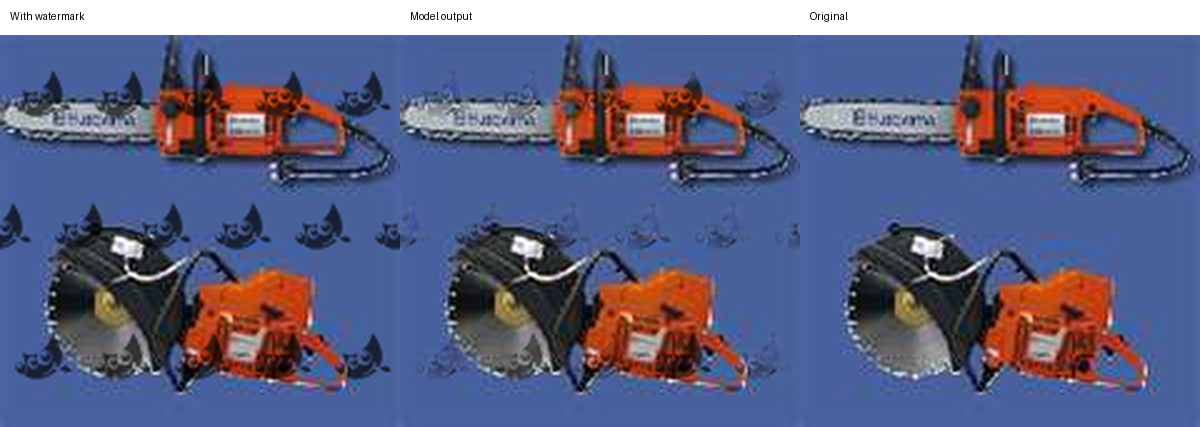

Test photo: n03417042_29310.JPEG — best validation epoch 19


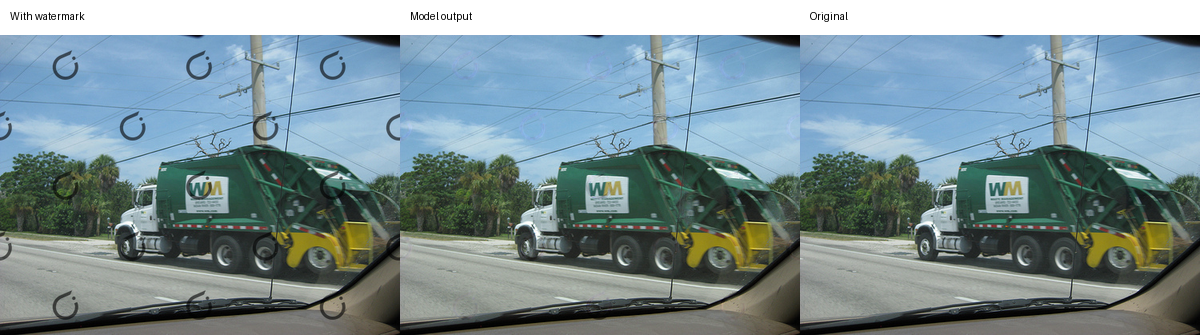

Test photo: n03000684_13813.JPEG — best validation epoch 19


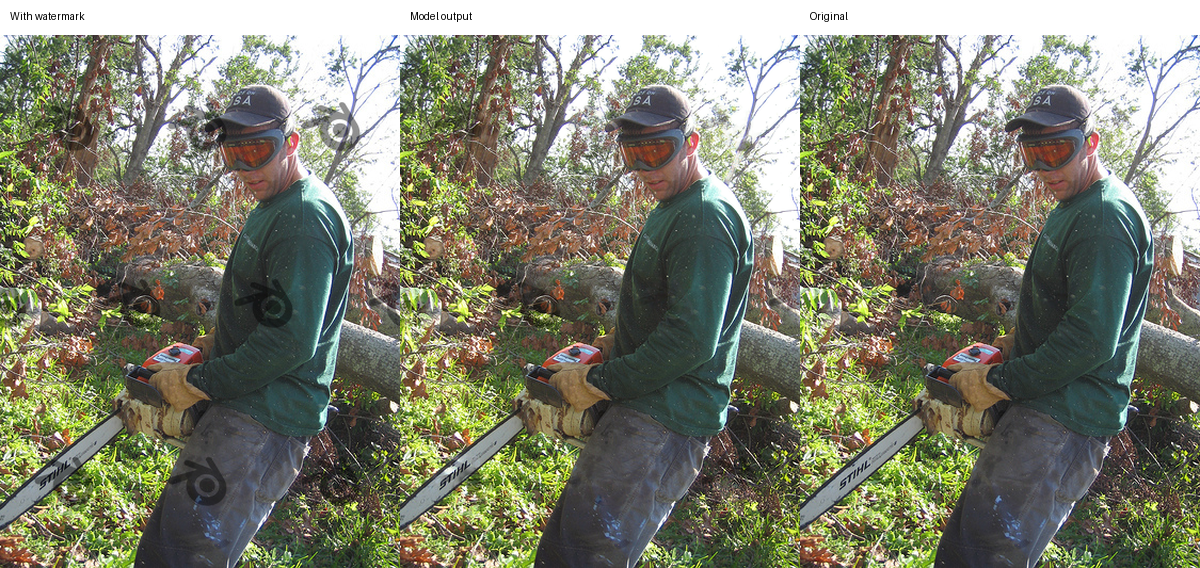

In [ ]:
# Run after training: held-out photos at their original dimensions.
assert globals().get('training_complete', False), 'Run the training cell to completion first.'
PREVIEW_COUNT = 3
DISPLAY_WIDTH = 400  # Display only; inference uses original dimensions.
# One variant per source photo, so the preview shows distinct test images.
preview_sources = {}
for record in test_rows:
    preview_sources.setdefault(record['source_sha256'], record)
preview_rows = random.Random(TRAIN_SEED).sample(
    list(preview_sources.values()), min(PREVIEW_COUNT, len(preview_sources)))
model.eval()
for record in preview_rows:
    watermarked = load_rgb_tensor(DATASET_DIR / record['watermarked'])
    with torch.inference_mode():
        prediction = model(watermarked[None].to(DEVICE))[0].cpu().clamp(0, 1)
    predicted_image = Image.fromarray(
        (prediction.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8))
    with Image.open(DATASET_DIR / record['watermarked']) as image:
        input_image = image.convert('RGB')
    with Image.open(DATASET_DIR / record['clean']) as image:
        original_image = image.convert('RGB')
    panel_height = max(1, round(input_image.height * DISPLAY_WIDTH / input_image.width))
    canvas = Image.new('RGB', (DISPLAY_WIDTH * 3, panel_height + 35), 'white')
    draw = ImageDraw.Draw(canvas)
    for column, (label, image) in enumerate([
        ('With watermark', input_image), ('Model output', predicted_image), ('Original', original_image)
    ]):
        x = column * DISPLAY_WIDTH
        draw.text((x + 10, 10), label, fill='black')
        canvas.paste(image.resize((DISPLAY_WIDTH, panel_height), Image.Resampling.LANCZOS), (x, 35))
    print(f"Test photo: {Path(record['source']).name} — best validation epoch {best_epoch}")
    display(canvas)


In [27]:
# Run after training to save the current model weights.
from pathlib import Path

MODELS_DIR = Path('models')
MODELS_DIR.mkdir(parents=True, exist_ok=True)
WEIGHTS_PATH = MODELS_DIR / 'decent_v1.pt'
# CPU tensors make the saved weights portable across CPU, MPS, and CUDA.
torch.save(
    {name: tensor.detach().cpu() for name, tensor in model.state_dict().items()},
    WEIGHTS_PATH,
)
print(f'Saved model weights to {WEIGHTS_PATH.resolve()}')

# To restore, instantiate WatermarkUNet with the same BASE_CHANNELS, then:
# model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=DEVICE, weights_only=True))
# model.eval()


Saved model weights to /Users/jacoberard/Documents/projects/ml_models/image_models/models/decent_v1.pt
